# 25장 · 컴퓨터 속 데이터는 왜 이산인가 — 해상도가 모양을 바꾼다

이산위상 연구실 활용 편 · 글 안상선. 그대로 위에서부터 실행하면 돼요.

In [1]:
# 처음 한 번만: 필요한 패키지 설치 (구글 코랩이면 앞에 !를 붙여 그대로 실행)
# pip install numpy scipy matplotlib scikit-image networkx trimesh ripser

연속인 고리(도넛 단면)를 여러 해상도의 픽셀 그림으로 바꾸고, **덩어리 수**와 **구멍 수**가 지켜지는지 셉니다. 덩어리는 대각선까지 이웃(8-이웃), 바깥 빈 곳은 가로세로 이웃(4-이웃)으로 셉니다(12장).

In [2]:
import numpy as np
from scipy import ndimage

def ring(N, r_in=0.25, r_out=0.36):
    """[0,1]x[0,1] 위의 고리를 N x N 픽셀로 (픽셀 가운데가 고리 안이면 1)"""
    c = (np.arange(N) + 0.5) / N
    X, Y = np.meshgrid(c, c)
    r = np.hypot(X - 0.5, Y - 0.5)
    return ((r >= r_in) & (r <= r_out)).astype(int)

def count(G):
    obj, n_obj = ndimage.label(G, structure=np.ones((3, 3)))          # 8-이웃
    bg, n_bg = ndimage.label(1 - G)                                     # 4-이웃(기본값)
    border = set(np.unique(np.concatenate([bg[0], bg[-1], bg[:, 0], bg[:, -1]]))) - {0}
    return n_obj, n_bg - len(border)                                    # 덩어리, 구멍

for N in [4, 6, 8, 12, 16, 24, 48]:
    n_obj, holes = count(ring(N))
    print(f"{N:>2} x {N:<2}  덩어리 {n_obj}  구멍 {holes}  {'OK' if (n_obj, holes) == (1, 1) else '모양이 바뀜'}")

 4 x 4   덩어리 0  구멍 0  모양이 바뀜
 6 x 6   덩어리 1  구멍 1  OK
 8 x 8   덩어리 1  구멍 1  OK
12 x 12  덩어리 1  구멍 1  OK
16 x 16  덩어리 1  구멍 1  OK
24 x 24  덩어리 1  구멍 1  OK
48 x 48  덩어리 1  구멍 1  OK


해상도가 너무 낮으면 고리가 끊기거나 구멍이 막혀서 「덩어리 1, 구멍 1」이 깨집니다. 컴퓨터가 연속인 세상을 이산 데이터로 저장할 때 모양(위상)이 바뀔 수 있다는 뜻이에요.

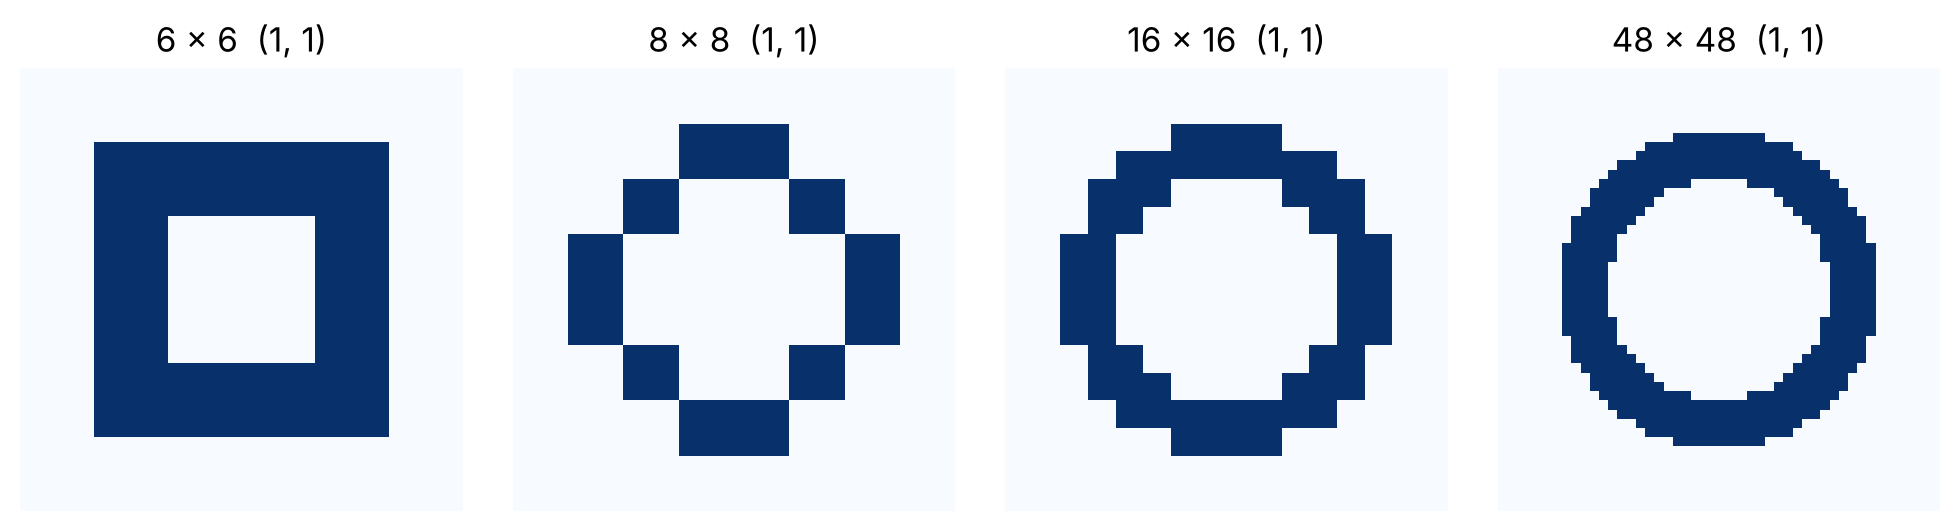

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 4, figsize=(10, 2.6))
for a, N in zip(ax, [6, 8, 16, 48]):
    a.imshow(ring(N), cmap='Blues'); a.set_title(f"{N} x {N}  {count(ring(N))}"); a.axis('off')
plt.tight_layout(); plt.show()